# GameTheory-04-NashEquilibrium-Python

**Navigation** : [<< 3-Topology2x2](GameTheory-03-Topology2x2-Python.ipynb) | [Index](README.md) | [5-ZeroSum-Minimax >>](GameTheory-05-ZeroSum-Minimax-Python.ipynb)

**Side tracks** : [4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) | [4c-NashExistence-Python](GameTheory-04c-NashExistence-Python.ipynb) | [4i-Utilite-Esperee-Risque](GameTheory-04i-Utilite-Esperee-Risque-Python.ipynb) | [4j-Rationalisabilite](GameTheory-04j-Rationalisabilite-Python.ipynb)

## Equilibres de Nash : Purs et Mixtes

Ce notebook explore en profondeur les **equilibres de Nash**, concept central de la théorie des jeux.

### Objectifs d'apprentissage

1. Définir formellement l'equilibre de Nash
2. Calculer les equilibres purs par best response
3. Introduire les stratégies mixtes
4. Calculer les equilibres mixtes
5. Utiliser les algorithmes : Support Enumeration, Lemke-Howson
6. Analyser parametriquement les equilibres

### Prerequis

- Notebooks 1-3 : Fondations, jeux en forme normale, topologie des jeux 2x2
- Notion de best response et de stratégie dominante
- Bases de l'algebre lineaire (produit matriciel)

### Duree estimee : 60 minutes

### Theoreme de Nash (1950)
> Tout jeu fini a au moins un equilibre de Nash (potentiellement en stratégies mixtes).

**Source primaire.** L'existence de l'equilibre de Nash est demontree par John F. Nash dans *Equilibrium Points in N-Person Games* (Proceedings of the National Academy of Sciences 36(1):48-49, 1950 ; DOI 10.1073/pnas.36.1.48), puis developpee en pleine generalite dans *Non-Cooperative Games* (Annals of Mathematics 54(2):286-295, 1951). L'existence repose sur le theoreme du point fixe de Brouwer (point fixe de la meilleure reponse), detaille dans le side track Lean [4b-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb).

## Références

**Osborne & Rubinstein (1994)**, ch. 2 « Nash Equilibrium » : §2.1 « Strategic Games » (p. 11), §2.2 « Nash Equilibrium », §2.4 « Existence of a Nash Equilibrium » ; §2.5 « Strictly Competitive Games » pour le versant zéro-sum. **Leyton-Brown & Shoham (2008)**, ch. 2 « Analyzing Games: From Optimality To Equilibrium » (§2.1 Pareto optimalité, §2.2 meilleure réponse et équilibre de Nash, §2.3 recherche des équilibres) — le condensé. Gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\`.

In [1]:
# Imports
import numpy as np
import nashpy as nash
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from typing import List, Tuple, Optional
import warnings
warnings.filterwarnings('ignore')
print("Imports OK : numpy, scipy, itertools")


Imports OK : numpy, scipy, itertools


## 1. Definition formelle

### Equilibre de Nash

Un profil de stratégies $\sigma^* = (\sigma_1^*, \sigma_2^*, ..., \sigma_n^*)$ est un **equilibre de Nash** si :

$$u_i(\sigma_i^*, \sigma_{-i}^*) \geq u_i(\sigma_i, \sigma_{-i}^*) \quad \forall i \in N, \forall \sigma_i \in \Sigma_i$$

Autrement dit, **aucun joueur n'a intérêt a devier unilateralement**.

### Types d'equilibres

| Type | Description |
|------|-------------|
| **Nash pur** | Chaque joueur joue une action déterministe |
| **Nash mixte** | Au moins un joueur randomise entre plusieurs actions |

In [2]:
class Game2x2:
    """
    Jeu 2x2 avec calcul d'equilibres.
    """
    
    def __init__(self, A: np.ndarray, B: np.ndarray, 
                 row_labels: List[str] = None,
                 col_labels: List[str] = None,
                 name: str = "Game"):
        self.A = np.array(A, dtype=float)
        self.B = np.array(B, dtype=float)
        self.name = name
        self.row_labels = row_labels or ['R0', 'R1']
        self.col_labels = col_labels or ['C0', 'C1']
        
        # Jeu Nashpy pour algorithmes
        self.nash_game = nash.Game(self.A, self.B)
    
    def payoffs(self, sigma_row: np.ndarray, sigma_col: np.ndarray) -> Tuple[float, float]:
        """Calcule les gains esperes pour des strategies mixtes."""
        u_row = sigma_row @ self.A @ sigma_col
        u_col = sigma_row @ self.B @ sigma_col
        return u_row, u_col
    
    def best_response_row(self, sigma_col: np.ndarray) -> np.ndarray:
        """Meilleure reponse de Row a la strategie mixte de Col."""
        expected = self.A @ sigma_col
        max_val = np.max(expected)
        # Retourne une strategie pure (BR peut etre multiple)
        return np.array([1.0, 0.0]) if expected[0] >= expected[1] else np.array([0.0, 1.0])
    
    def best_response_col(self, sigma_row: np.ndarray) -> np.ndarray:
        """Meilleure reponse de Col a la strategie mixte de Row."""
        expected = sigma_row @ self.B
        max_val = np.max(expected)
        return np.array([1.0, 0.0]) if expected[0] >= expected[1] else np.array([0.0, 1.0])
    
    def display(self):
        """Affiche le jeu."""
        print(f"\n{self.name}")
        print("=" * 40)
        print(f"            {self.col_labels[0]:>12} {self.col_labels[1]:>12}")
        for i, label in enumerate(self.row_labels):
            print(f"{label:>10}  ({self.A[i,0]:>4.1f},{self.B[i,0]:>4.1f})  ({self.A[i,1]:>4.1f},{self.B[i,1]:>4.1f})")

# Exemples
pd = Game2x2(
    A=[[3, 0], [5, 1]],
    B=[[3, 5], [0, 1]],
    row_labels=['Cooperer', 'Defaire'],
    col_labels=['Cooperer', 'Defaire'],
    name="Dilemme du Prisonnier"
)
pd.display()


Dilemme du Prisonnier
                Cooperer      Defaire
  Cooperer  ( 3.0, 3.0)  ( 0.0, 5.0)
   Defaire  ( 5.0, 0.0)  ( 1.0, 1.0)


## 2. Equilibres de Nash purs

Un equilibre en stratégies **pures** est une paire d'actions $(i^*, j^*)$ telle que :
- $A_{i^*, j^*} \geq A_{i, j^*}$ pour tout $i$ (Row joue best response)
- $B_{i^*, j^*} \geq B_{i^*, j}$ pour tout $j$ (Col joue best response)

In [3]:
def find_pure_nash(game: Game2x2) -> List[Tuple[int, int]]:
    """
    Trouve tous les equilibres de Nash purs par enumeration.
    """
    equilibria = []
    m, n = game.A.shape
    
    for i in range(m):
        for j in range(n):
            # i est meilleure reponse a j ?
            row_br = all(game.A[i, j] >= game.A[k, j] for k in range(m))
            # j est meilleure reponse a i ?
            col_br = all(game.B[i, j] >= game.B[i, l] for l in range(n))
            
            if row_br and col_br:
                equilibria.append((i, j))
    
    return equilibria

def display_equilibria(game: Game2x2):
    """Affiche les equilibres d'un jeu."""
    game.display()
    
    pure_eq = find_pure_nash(game)
    print(f"\nEquilibres de Nash purs: {len(pure_eq)}")
    
    for (i, j) in pure_eq:
        u_row, u_col = game.A[i, j], game.B[i, j]
        print(f"  ({game.row_labels[i]}, {game.col_labels[j]}) -> gains ({u_row}, {u_col})")

# Tester sur plusieurs jeux
games = [
    Game2x2([[3,0],[5,1]], [[3,5],[0,1]], ['C','D'], ['C','D'], "Prisoner's Dilemma"),
    Game2x2([[4,0],[3,3]], [[4,3],[0,3]], ['Stag','Hare'], ['Stag','Hare'], "Stag Hunt"),
    Game2x2([[3,0],[0,2]], [[2,0],[0,3]], ['Opera','Football'], ['Opera','Football'], "Battle of Sexes"),
    Game2x2([[1,-1],[-1,1]], [[-1,1],[1,-1]], ['Pile','Face'], ['Pile','Face'], "Matching Pennies"),
]

for g in games:
    display_equilibria(g)
    print()


Prisoner's Dilemma
                       C            D
         C  ( 3.0, 3.0)  ( 0.0, 5.0)
         D  ( 5.0, 0.0)  ( 1.0, 1.0)

Equilibres de Nash purs: 1
  (D, D) -> gains (1.0, 1.0)


Stag Hunt
                    Stag         Hare
      Stag  ( 4.0, 4.0)  ( 0.0, 3.0)
      Hare  ( 3.0, 0.0)  ( 3.0, 3.0)

Equilibres de Nash purs: 2
  (Stag, Stag) -> gains (4.0, 4.0)
  (Hare, Hare) -> gains (3.0, 3.0)


Battle of Sexes
                   Opera     Football
     Opera  ( 3.0, 2.0)  ( 0.0, 0.0)
  Football  ( 0.0, 0.0)  ( 2.0, 3.0)

Equilibres de Nash purs: 2
  (Opera, Opera) -> gains (3.0, 2.0)
  (Football, Football) -> gains (2.0, 3.0)


Matching Pennies
                    Pile         Face
      Pile  ( 1.0,-1.0)  (-1.0, 1.0)
      Face  (-1.0, 1.0)  ( 1.0,-1.0)

Equilibres de Nash purs: 0



### Analyse des equilibres purs

Les résultats ci-dessus illustrent les **quatre types fondamentaux** de jeux 2x2 :

| Jeu | Nash purs | Interpretation |
|-----|-----------|----------------|
| **Prisoner's Dilemma** | 1 (D,D) | Equilibre unique mais sous-optimal - le "dilemme" |
| **Stag Hunt** | 2 | Problème de **coordination** - quel equilibre choisir ? |
| **Battle of Sexes** | 2 | Problème de **sélection** - intérêts partiellement alignes |
| **Matching Pennies** | 0 | Conflit pur - equilibre mixte obligatoire |

**Question fondamentale** : Quand un jeu a **plusieurs equilibres**, comment les joueurs se coordonnent-ils ?

- **Focal points** (Schelling) : Certains equilibres sont plus "saillants" culturellement
- **Communication** : Parler avant de jouer peut aider (mais pas toujours)
- **Histoire** : Les interactions passees créent des précédents

**Quand il n'y a aucun equilibre pur** (Matching Pennies) : Les joueurs doivent randomiser pour ne pas etre previsibles. C'est la base des stratégies mixtes.

### Exercice : Elimination iterative des stratégies dominees

**Objectif** : Implementer l'elimination iterative des stratégies strictement dominees pour un jeu 2x2, puis verifier que les stratégies survivantes correspondent aux equilibres de Nash purs trouves par `find_pure_nash`.

**Contexte** : Dans le Dilemme du Prisonnier, Defaire domine Cooperer. Après elimination, il ne reste qu'un seul profil : (D,D), qui est l'equilibre de Nash.

- **Indice :** Pour chaque joueur, comparer les gains de chaque action contre toutes les actions de l'adversaire.
- **Étape 1 :** Identifier les stratégies strictement dominees pour chaque joueur.
- **Étape 2 :** Les eliminer et verifier si de nouvelles dominations apparaissent.
- **Étape 3 :** Comparer les stratégies survivantes avec les equilibres de Nash.

In [4]:
def exercice_dominance_iteree(A: np.ndarray, B: np.ndarray) -> dict:
    """
    Elimination iterative des strategies strictement dominees.
    
    Args:
        A: matrice des gains du joueur Row (m x n)
        B: matrice des gains du joueur Col (m x n)
    
    Returns:
        dict avec :
            'surviving_row': liste des indices de lignes survivantes
            'surviving_col': liste des indices de colonnes survivantes
            'nash_profiles': liste des profils (i,j) survivants
    """
    return {"surviving_row": [], "surviving_col": [], "nash_profiles": []}  # TODO etudiant

# Test : Dilemme du Prisonnier
A_pd = np.array([[3, 0], [5, 1]])
B_pd = np.array([[3, 5], [0, 1]])
result_pd = exercice_dominance_iteree(A_pd, B_pd)
print(f"PD - Survivants Row: {result_pd['surviving_row']}, Col: {result_pd['surviving_col']}")
print(f"PD - Profils survivants: {result_pd['nash_profiles']}")

# Test : Stag Hunt (pas de domination)
A_sh = np.array([[4, 0], [3, 3]])
B_sh = np.array([[4, 3], [0, 3]])
result_sh = exercice_dominance_iteree(A_sh, B_sh)
print(f"\nStag Hunt - Survivants Row: {result_sh['surviving_row']}, Col: {result_sh['surviving_col']}")

print("Exercice a completer")

PD - Survivants Row: [], Col: []
PD - Profils survivants: []

Stag Hunt - Survivants Row: [], Col: []
Exercice a completer


## 3. Stratégies mixtes

### Definition

Une **stratégie mixte** est une distribution de probabilite sur les actions pures.

Pour un joueur avec actions $\{1, ..., m\}$, une stratégie mixte est $\sigma = (\sigma_1, ..., \sigma_m)$ avec :
- $\sigma_i \geq 0$ pour tout $i$
- $\sum_i \sigma_i = 1$

### Gain espere

Le gain espere du joueur Row avec stratégies mixtes $(\sigma, \tau)$ est :
$$u_{Row}(\sigma, \tau) = \sigma^T A \tau = \sum_{i,j} \sigma_i \tau_j A_{ij}$$

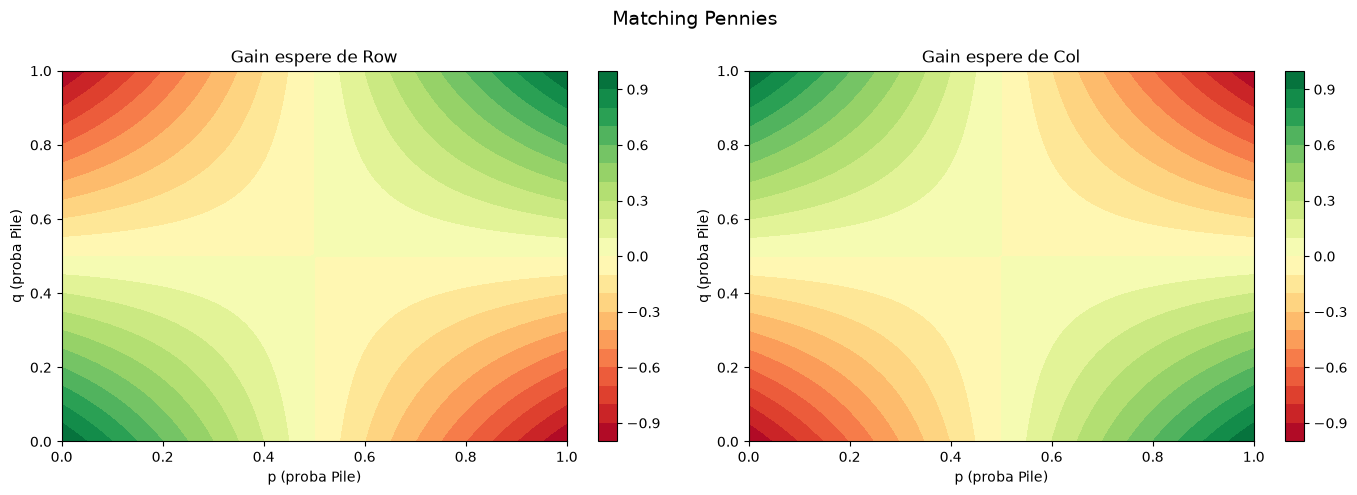

In [5]:
def visualize_mixed_strategies(game: Game2x2):
    """
    Visualise les gains en fonction des strategies mixtes.
    
    Pour un jeu 2x2, on peut parametrer:
    - sigma_row = (p, 1-p) avec p in [0,1]
    - sigma_col = (q, 1-q) avec q in [0,1]
    """
    p_vals = np.linspace(0, 1, 100)
    q_vals = np.linspace(0, 1, 100)
    P, Q = np.meshgrid(p_vals, q_vals)
    
    # Calcul des gains esperes
    U_row = np.zeros_like(P)
    U_col = np.zeros_like(P)
    
    for i, p in enumerate(p_vals):
        for j, q in enumerate(q_vals):
            sigma_row = np.array([p, 1-p])
            sigma_col = np.array([q, 1-q])
            U_row[j, i], U_col[j, i] = game.payoffs(sigma_row, sigma_col)
    
    # Visualisation
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Gain Row
    im0 = axes[0].contourf(P, Q, U_row, levels=20, cmap='RdYlGn')
    plt.colorbar(im0, ax=axes[0])
    axes[0].set_xlabel(f'p (proba {game.row_labels[0]})')
    axes[0].set_ylabel(f'q (proba {game.col_labels[0]})')
    axes[0].set_title(f'Gain espere de Row')
    
    # Gain Col
    im1 = axes[1].contourf(P, Q, U_col, levels=20, cmap='RdYlGn')
    plt.colorbar(im1, ax=axes[1])
    axes[1].set_xlabel(f'p (proba {game.row_labels[0]})')
    axes[1].set_ylabel(f'q (proba {game.col_labels[0]})')
    axes[1].set_title(f'Gain espere de Col')
    
    fig.suptitle(game.name, fontsize=14)
    plt.tight_layout()
    plt.show()

# Visualiser Matching Pennies
mp = Game2x2([[1,-1],[-1,1]], [[-1,1],[1,-1]], ['Pile','Face'], ['Pile','Face'], "Matching Pennies")
visualize_mixed_strategies(mp)

## 4. Calcul des equilibres mixtes

### Condition d'indifference

A l'equilibre mixte, un joueur qui joue plusieurs actions avec probabilite positive doit etre **indifferent** entre ces actions.

Pour le joueur Row jouant $(p, 1-p)$ contre Col jouant $(q, 1-q)$ :
- Gain de Row en jouant action 0 : $A_{00}q + A_{01}(1-q)$
- Gain de Row en jouant action 1 : $A_{10}q + A_{11}(1-q)$

A l'equilibre mixte (si $0 < p < 1$), ces deux gains sont egaux.

In [6]:
def compute_mixed_nash_2x2(game: Game2x2) -> Optional[Tuple[np.ndarray, np.ndarray]]:
    """
    Calcule l'equilibre mixte d'un jeu 2x2 par la condition d'indifference.
    
    Returns:
        (sigma_row, sigma_col) ou None si pas d'equilibre mixte interieur.
    """
    A, B = game.A, game.B
    
    # Condition d'indifference pour Row:
    # A[0,0]*q + A[0,1]*(1-q) = A[1,0]*q + A[1,1]*(1-q)
    # (A[0,0] - A[0,1] - A[1,0] + A[1,1]) * q = A[1,1] - A[0,1]
    
    denom_q = A[0,0] - A[0,1] - A[1,0] + A[1,1]
    if abs(denom_q) < 1e-10:
        return None  # Pas de solution unique
    
    q = (A[1,1] - A[0,1]) / denom_q
    
    # Condition d'indifference pour Col:
    # B[0,0]*p + B[1,0]*(1-p) = B[0,1]*p + B[1,1]*(1-p)
    
    denom_p = B[0,0] - B[1,0] - B[0,1] + B[1,1]
    if abs(denom_p) < 1e-10:
        return None
    
    p = (B[1,1] - B[1,0]) / denom_p
    
    # Verifier que c'est un equilibre interieur valide
    if 0 <= p <= 1 and 0 <= q <= 1:
        sigma_row = np.array([p, 1-p])
        sigma_col = np.array([q, 1-q])
        return sigma_row, sigma_col
    
    return None

# Tester sur Matching Pennies
mp = Game2x2([[1,-1],[-1,1]], [[-1,1],[1,-1]], ['Pile','Face'], ['Pile','Face'], "Matching Pennies")
mp.display()

mixed_eq = compute_mixed_nash_2x2(mp)
if mixed_eq:
    sigma_row, sigma_col = mixed_eq
    print(f"\nEquilibre mixte:")
    print(f"  Row: ({sigma_row[0]:.3f}, {sigma_row[1]:.3f})")
    print(f"  Col: ({sigma_col[0]:.3f}, {sigma_col[1]:.3f})")
    print(f"  Gains esperes: {mp.payoffs(sigma_row, sigma_col)}")


Matching Pennies
                    Pile         Face
      Pile  ( 1.0,-1.0)  (-1.0, 1.0)
      Face  (-1.0, 1.0)  ( 1.0,-1.0)

Equilibre mixte:
  Row: (0.500, 0.500)
  Col: (0.500, 0.500)
  Gains esperes: (np.float64(0.0), np.float64(0.0))


### Interpretation : L'equilibre mixte de Matching Pennies

Le résultat $(0.5, 0.5)$ pour les deux joueurs est **l'unique equilibre** de ce jeu.

**Pourquoi 50-50 ?**
- Si un joueur devie (ex: joue Pile a 60%), l'adversaire peut exploiter cette regularite
- A l'equilibre, chaque joueur est **indifferent** entre Pile et Face
- Cette indifference garantit que l'adversaire ne peut pas predire votre choix

**Gain espere = 0** : Le jeu est parfaitement equilibre, aucun joueur n'a d'avantage a long terme.

| Propriete | Valeur |
|-----------|--------|
| Stratégie Row | (0.5, 0.5) |
| Stratégie Col | (0.5, 0.5) |
| Gain espere Row | 0 |
| Gain espere Col | 0 |

> **Note** : Ce résultat est fondamental en théorie des jeux. Il montre que même dans un jeu de pur conflit, un comportement "rationnel" emerge : la randomisation optimale.

In [7]:
# Calculer tous les equilibres (purs et mixtes) pour plusieurs jeux
def analyze_all_equilibria(game: Game2x2):
    """Analyse complete des equilibres."""
    game.display()
    
    # Equilibres purs
    pure_eq = find_pure_nash(game)
    print(f"\nEquilibres purs: {len(pure_eq)}")
    for (i, j) in pure_eq:
        print(f"  ({game.row_labels[i]}, {game.col_labels[j]})")
    
    # Equilibre mixte
    mixed_eq = compute_mixed_nash_2x2(game)
    if mixed_eq:
        sigma_row, sigma_col = mixed_eq
        # Verifier que c'est vraiment un equilibre interieur
        if 0 < sigma_row[0] < 1 and 0 < sigma_col[0] < 1:
            u_row, u_col = game.payoffs(sigma_row, sigma_col)
            print(f"\nEquilibre mixte:")
            print(f"  Row: {sigma_row} (p={sigma_row[0]:.3f})")
            print(f"  Col: {sigma_col} (q={sigma_col[0]:.3f})")
            print(f"  Gains: ({u_row:.3f}, {u_col:.3f})")
    else:
        print("\nPas d'equilibre mixte interieur")
    
    print()

# Analyser les jeux classiques
for g in games:
    analyze_all_equilibria(g)
    print("-" * 50)


Prisoner's Dilemma
                       C            D
         C  ( 3.0, 3.0)  ( 0.0, 5.0)
         D  ( 5.0, 0.0)  ( 1.0, 1.0)

Equilibres purs: 1
  (D, D)

Pas d'equilibre mixte interieur

--------------------------------------------------

Stag Hunt
                    Stag         Hare
      Stag  ( 4.0, 4.0)  ( 0.0, 3.0)
      Hare  ( 3.0, 0.0)  ( 3.0, 3.0)

Equilibres purs: 2
  (Stag, Stag)
  (Hare, Hare)

Equilibre mixte:
  Row: [0.75 0.25] (p=0.750)
  Col: [0.75 0.25] (q=0.750)
  Gains: (3.000, 3.000)

--------------------------------------------------

Battle of Sexes
                   Opera     Football
     Opera  ( 3.0, 2.0)  ( 0.0, 0.0)
  Football  ( 0.0, 0.0)  ( 2.0, 3.0)

Equilibres purs: 2
  (Opera, Opera)
  (Football, Football)

Equilibre mixte:
  Row: [0.6 0.4] (p=0.600)
  Col: [0.4 0.6] (q=0.400)
  Gains: (1.200, 1.200)

--------------------------------------------------

Matching Pennies
                    Pile         Face
      Pile  ( 1.0,-1.0)  (-1.0, 1.0)

### Interpretation des equilibres mixtes

Les résultats revelent des proprietes fondamentales des equilibres mixtes :

**Prisoner's Dilemma** : Pas d'equilibre mixte interieur
- Pourquoi ? Parce que Defaire **domine** Cooperer
- Si une stratégie domine, pas besoin de mixer

**Stag Hunt** : Equilibre mixte (75%, 25%)
- Les joueurs jouent Stag avec proba 75%
- Gain espere = 3 (egal au gain de Hare,Hare)
- **Paradoxe** : L'equilibre mixte donne le même gain que le "mauvais" equilibre pur !

**Battle of Sexes** : Equilibre mixte (60%, 40%)
- Row joue Opera plus souvent car il prefere Opera
- Mais le gain espere (1.2) est **inferieur** aux deux equilibres purs !
- C'est le **cout de la mis-coordination**

**Matching Pennies** : Equilibre mixte (50%, 50%)
- Seul equilibre du jeu
- Gain espere = 0 (jeu equitable)
- Toute deviation est **exploitable** par l'adversaire

**Lecon cle** : L'equilibre mixte n'est pas un "compromis" - c'est le point ou chaque joueur est **indifferent** entre ses actions, donc ne peut pas etre exploite.

## 5. Algorithmes de Nashpy

Nashpy implemente plusieurs algorithmes pour trouver les equilibres de Nash.

In [8]:
def compare_nash_algorithms(game: Game2x2):
    """
    Compare les algorithmes de Nashpy pour trouver les equilibres.
    """
    print(f"\n{game.name}")
    print("=" * 50)
    
    # 1. Support Enumeration
    print("\n1. Support Enumeration:")
    for eq in game.nash_game.support_enumeration():
        sigma_row, sigma_col = eq
        u = game.payoffs(sigma_row, sigma_col)
        print(f"   Row: {np.round(sigma_row, 4)}, Col: {np.round(sigma_col, 4)}, Gains: {np.round(u, 4)}")
    
    # 2. Lemke-Howson
    print("\n2. Lemke-Howson:")
    try:
        for eq in game.nash_game.lemke_howson_enumeration():
            sigma_row, sigma_col = eq
            u = game.payoffs(sigma_row, sigma_col)
            print(f"   Row: {np.round(sigma_row, 4)}, Col: {np.round(sigma_col, 4)}, Gains: {np.round(u, 4)}")
    except Exception as e:
        print(f"   Erreur: {e}")
    
    # 3. Vertex Enumeration
    print("\n3. Vertex Enumeration:")
    try:
        for eq in game.nash_game.vertex_enumeration():
            sigma_row, sigma_col = eq
            u = game.payoffs(sigma_row, sigma_col)
            print(f"   Row: {np.round(sigma_row, 4)}, Col: {np.round(sigma_col, 4)}, Gains: {np.round(u, 4)}")
    except Exception as e:
        print(f"   Erreur: {e}")

# Comparer sur Battle of the Sexes (2 purs + 1 mixte)
bos = Game2x2([[3,0],[0,2]], [[2,0],[0,3]], ['Opera','Football'], ['Opera','Football'], "Battle of Sexes")
compare_nash_algorithms(bos)


Battle of Sexes

1. Support Enumeration:
   Row: [1. 0.], Col: [1. 0.], Gains: [3. 2.]
   Row: [0. 1.], Col: [0. 1.], Gains: [2. 3.]
   Row: [0.6 0.4], Col: [0.4 0.6], Gains: [1.2 1.2]

2. Lemke-Howson:
   Row: [1. 0.], Col: [1. 0.], Gains: [3. 2.]
   Row: [0. 1.], Col: [0. 1.], Gains: [2. 3.]
   Row: [1. 0.], Col: [1. 0.], Gains: [3. 2.]
   Row: [0. 1.], Col: [0. 1.], Gains: [2. 3.]

3. Vertex Enumeration:
   Row: [ 1. -0.], Col: [1. 0.], Gains: [3. 2.]
   Row: [0. 1.], Col: [-0.  1.], Gains: [2. 3.]
   Row: [0.6 0.4], Col: [0.4 0.6], Gains: [1.2 1.2]


## 6. Analyse parametrique

Comment les equilibres changent-ils quand on modifie les gains ?

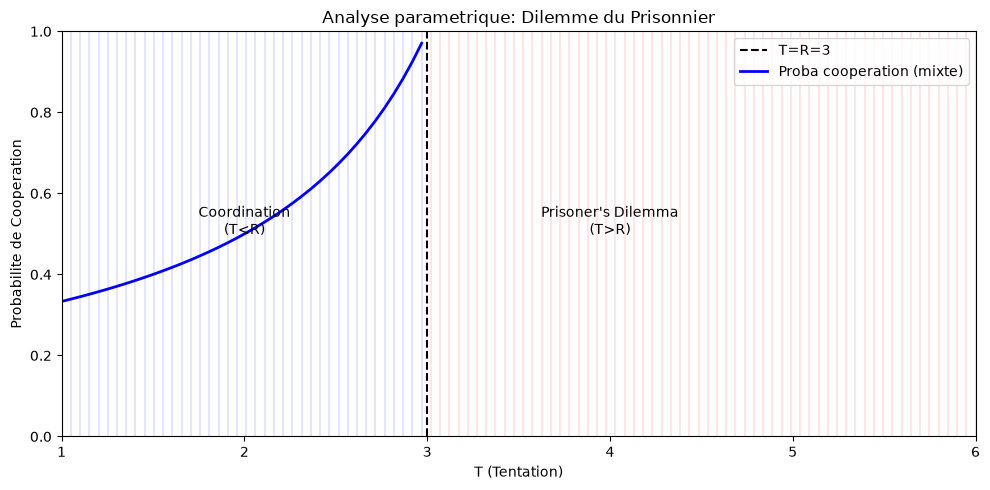

In [9]:
def parametric_analysis_pd(T_range: np.ndarray):
    """
    Analyse parametrique du Dilemme du Prisonnier.
    
    Matrice standard:
        (R, R)  (S, T)
        (T, S)  (P, P)
    
    Avec T > R > P > S (tentaion, reward, punishment, sucker)
    On fixe R=3, P=1, S=0 et on varie T.
    """
    R, P, S = 3, 1, 0
    
    equilibrium_types = []
    mixed_probs = []
    
    for T in T_range:
        A = np.array([[R, S], [T, P]])
        B = np.array([[R, T], [S, P]])
        game = Game2x2(A, B)
        
        pure_eq = find_pure_nash(game)
        mixed_eq = compute_mixed_nash_2x2(game)
        
        # Classifier le type de jeu
        if len(pure_eq) == 1 and pure_eq[0] == (1, 1):
            if T > R:  # Prisoner's Dilemma
                eq_type = 'PD'
            else:  # Harmony
                eq_type = 'Harmony'
        elif len(pure_eq) == 2:
            eq_type = 'Coord'
        else:
            eq_type = 'Other'
        
        equilibrium_types.append(eq_type)
        
        if mixed_eq and 0 < mixed_eq[0][0] < 1:
            mixed_probs.append(mixed_eq[0][0])
        else:
            mixed_probs.append(np.nan)
    
    # Visualisation
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Marquer les regions
    colors = {'PD': 'red', 'Harmony': 'green', 'Coord': 'blue', 'Other': 'gray'}
    for i, (T, eq_type) in enumerate(zip(T_range, equilibrium_types)):
        ax.axvline(T, color=colors.get(eq_type, 'gray'), alpha=0.1)
    
    # Ligne de separation T=R
    ax.axvline(R, color='black', linestyle='--', label=f'T=R={R}')
    
    # Probabilite de cooperation a l'equilibre mixte
    ax.plot(T_range, mixed_probs, 'b-', linewidth=2, label='Proba cooperation (mixte)')
    
    ax.set_xlabel('T (Tentation)')
    ax.set_ylabel('Probabilite de Cooperation')
    ax.set_title('Analyse parametrique: Dilemme du Prisonnier')
    ax.legend()
    ax.set_xlim(T_range[0], T_range[-1])
    ax.set_ylim(0, 1)
    
    # Annotations
    ax.annotate('Coordination\n(T<R)', xy=(2, 0.5), fontsize=10, ha='center')
    ax.annotate("Prisoner's Dilemma\n(T>R)", xy=(4, 0.5), fontsize=10, ha='center')
    
    plt.tight_layout()
    plt.show()

# Varier T de 1 a 6
parametric_analysis_pd(np.linspace(1, 6, 100))

### Interpretation : Impact du paramètre de Tentation

Le graphique revele une **transition de phase** fondamentale dans la structure des equilibres :

| Region | Condition | Comportement |
|--------|-----------|--------------|
| **Coordination** | T < R (T < 3) | Deux équilibres purs : (C,C) Pareto-dominant et (D,D) |
| **Dilemme** | T > R (T > 3) | Defaire domine malgre le cout collectif |

**Observations cles** :
- La ligne verticale T = R = 3 marque la frontiere critique
- A gauche : pas de dilemme, la cooperation est naturelle
- A droite : le dilemme emerge, la tentation detruit la cooperation

> **Lecon pour le design de mécanismes** : Si vous concevez un système (contrat, règle, incitation), maintenir T < R garantit la cooperation sans enforcement externe. C'est le principe des "incentive-compatible mechanisms".

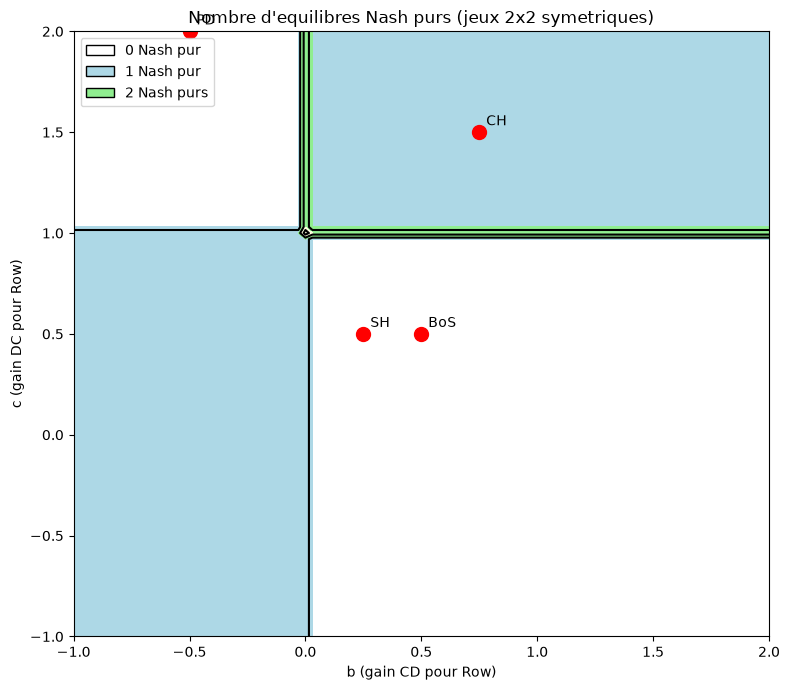

In [10]:
def visualize_equilibrium_regions():
    """
    Visualise les regions d'equilibres dans l'espace des parametres.
    
    Pour un jeu 2x2 symetrique avec gains (a,b,c,d) pour Row:
        (a, a)  (b, c)
        (c, b)  (d, d)
    
    On fixe a=1, d=0 et on varie b et c.
    """
    a, d = 1, 0
    b_range = np.linspace(-1, 2, 100)
    c_range = np.linspace(-1, 2, 100)
    B_grid, C_grid = np.meshgrid(b_range, c_range)
    
    n_pure_nash = np.zeros_like(B_grid)
    
    for i, b in enumerate(b_range):
        for j, c in enumerate(c_range):
            A_mat = np.array([[a, b], [c, d]])
            B_mat = np.array([[a, c], [b, d]])  # Symetrique
            game = Game2x2(A_mat, B_mat)
            pure_eq = find_pure_nash(game)
            n_pure_nash[j, i] = len(pure_eq)
    
    # Visualisation
    fig, ax = plt.subplots(figsize=(8, 7))
    
    im = ax.contourf(B_grid, C_grid, n_pure_nash, levels=[0, 1, 2, 3, 4], 
                     colors=['white', 'lightblue', 'lightgreen', 'lightyellow'])
    ax.contour(B_grid, C_grid, n_pure_nash, levels=[0.5, 1.5, 2.5, 3.5], colors='black')
    
    # Marquer les jeux classiques
    # PD: a=3, b=0, c=5, d=1 -> normalise (d=0, a=1) : a=1, b=-0.5, c=2.0, d=0
    classic_games = {
        'PD': (-0.5, 2.0),
        'SH': (0.25, 0.5),
        'BoS': (0.5, 0.5),
        'CH': (0.75, 1.5),
    }
    
    for name, (b, c) in classic_games.items():
        if b_range[0] <= b <= b_range[-1] and c_range[0] <= c <= c_range[-1]:
            ax.plot(b, c, 'ro', markersize=10)
            ax.annotate(name, (b, c), textcoords="offset points", xytext=(5,5))
    
    ax.set_xlabel('b (gain CD pour Row)')
    ax.set_ylabel('c (gain DC pour Row)')
    ax.set_title('Nombre d\'equilibres Nash purs (jeux 2x2 symetriques)')
    
    # Legende
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='white', edgecolor='black', label='0 Nash pur'),
        Patch(facecolor='lightblue', edgecolor='black', label='1 Nash pur'),
        Patch(facecolor='lightgreen', edgecolor='black', label='2 Nash purs'),
    ]
    ax.legend(handles=legend_elements, loc='upper left')
    
    plt.tight_layout()
    plt.show()

visualize_equilibrium_regions()

### Ce que nous apprend l'analyse parametrique

Les graphiques ci-dessus revelent une structure profonde :

**Transition de phase a T=R (Tentation = Recompense)** :
- **T < R** (gauche) : Le jeu est une "Coordination" - (C,C) est l'équilibre Pareto-dominant, mais (D,D) en est un aussi
- **T > R** (droite) : Le jeu devient un "Dilemme du Prisonnier"

C'est une **bifurcation** : un petit changement de paramètre transforme radicalement la dynamique du jeu.

**Regions dans l'espace (b,c)** :
- La **topologie** des equilibres depend des inegalites entre gains
- Les jeux classiques (PD, SH, BoS, CH) occupent des regions spécifiques
- Les frontieres correspondent a des **degenerescences** (equilibres multiples coincident)

**Application pratique** :
- Si vous concevez un mécanisme (encheres, contrat, etc.), l'analyse parametrique vous dit **ou sont les risques**
- Un petit changement d'incitation peut faire passer d'un monde cooperatif a un dilemme social
- Les concepteurs de mécanismes cherchent souvent a **eloigner** le système des frontieres critiques

## 7. Jeux plus grands : algorithme de support enumeration

Pour les jeux plus grands que 2x2, l'algorithme de **support enumeration** est plus general.

In [11]:
# Jeu 3x3: Pierre-Feuille-Ciseaux
A_rps = np.array([
    [0, -1, 1],
    [1, 0, -1],
    [-1, 1, 0]
])
B_rps = -A_rps  # Jeu a somme nulle

rps = nash.Game(A_rps, B_rps)

print("Pierre-Feuille-Ciseaux (3x3)")
print("="*40)
print("\nMatrice des gains (Row):")
print(A_rps)

print("\nEquilibres de Nash:")
for eq in rps.support_enumeration():
    sigma_row, sigma_col = eq
    print(f"\n  Row: {np.round(sigma_row, 4)}")
    print(f"  Col: {np.round(sigma_col, 4)}")
    u_row = sigma_row @ A_rps @ sigma_col
    print(f"  Gain Row: {u_row:.4f}")

Pierre-Feuille-Ciseaux (3x3)

Matrice des gains (Row):
[[ 0 -1  1]
 [ 1  0 -1]
 [-1  1  0]]

Equilibres de Nash:

  Row: [0.3333 0.3333 0.3333]
  Col: [0.3333 0.3333 0.3333]
  Gain Row: 0.0000


### Interpretation : Pierre-Feuille-Ciseaux

Le résultat confirme une propriete fondamentale des jeux a somme nulle symetriques :

**L'equilibre unique** est la stratégie mixte uniforme $(1/3, 1/3, 1/3)$ pour les deux joueurs.

**Pourquoi ?** La structure circulaire du jeu (Pierre bat Ciseaux, Ciseaux bat Feuille, Feuille bat Pierre) garantit qu'aucune action pure n'est meilleure qu'une autre. Toute stratégie non-uniforme serait exploitable :
- Si vous jouez Pierre plus souvent, l'adversaire joue Feuille
- Si vous jouez de maniere previsible, vous perdez en moyenne

**Gain espere = 0** : Le jeu est parfaitement equilibre. A l'equilibre, aucun joueur n'a d'avantage.

> **Application** : Ce résultat s'etend a tous les jeux de type "circulaire". Dans les sports ou competitions, les stratégies mixtes optimales sont souvent proches de l'uniformite quand il n'y a pas de "meilleure" option objective.

### Exercice : Pierre-Feuille-Ciseaux biaise

**Objectif** : Construire un jeu Pierre-Feuille-Ciseaux biaise ou gagner avec Pierre rapporte 2 au lieu de 1. Calculer l'equilibre mixte via `nash.Game(...).support_enumeration()` et verifier que la distribution n'est plus uniforme.

**Contexte** : L'exemple ci-dessus montre que le RPS standard a un equilibre uniforme (1/3, 1/3, 1/3). Que se passe-t-il si on desequilibre les gains ?

- **Indice :** Modifier la matrice A_rps pour que la ligne Pierre (index 0) batte Ciseaux avec gain 2 au lieu de 1.
- **Étape 1 :** Construire la matrice biaisee A_biased.
- **Étape 2 :** Calculer les equilibres avec support_enumeration.
- **Étape 3 :** Verifier que les probabilites différent de 1/3.

In [12]:
def exercice_nash_3x3_rps_biaise() -> dict:
    """
    Construit un RPS biaise (gain Pierre=2) et calcule l'equilibre mixte.
    
    Returns:
        dict avec :
            'A_biased': la matrice biaisee
            'sigma_row': strategie mixte de Row
            'sigma_col': strategie mixte de Col
            'is_uniform': True si (1/3, 1/3, 1/3), False sinon
    """
    print("Exercice a completer : exercice_nash_3x3_rps_biaise")
    return {"A_biased": None, "sigma_row": None, "sigma_col": None, "is_uniform": None}  # TODO etudiant

result_rps = exercice_nash_3x3_rps_biaise()
print(f"Matrice biaisee:\n{result_rps['A_biased']}")
print(f"\nSigma Row: {result_rps['sigma_row']}")
print(f"Sigma Col: {result_rps['sigma_col']}")
print(f"Uniforme ? {result_rps['is_uniform']}")


Exercice a completer : exercice_nash_3x3_rps_biaise
Matrice biaisee:
None

Sigma Row: None
Sigma Col: None
Uniforme ? None


In [13]:
# Jeu asymetrique 3x2
A_asym = np.array([
    [3, 1],
    [0, 4],
    [2, 2]
])
B_asym = np.array([
    [2, 3],
    [4, 1],
    [1, 2]
])

asym = nash.Game(A_asym, B_asym)

print("Jeu asymetrique 3x2")
print("="*40)
print("\nMatrice A (gains Row):")
print(A_asym)
print("\nMatrice B (gains Col):")
print(B_asym)

print("\nEquilibres de Nash:")
for i, eq in enumerate(asym.support_enumeration()):
    sigma_row, sigma_col = eq
    u_row = sigma_row @ A_asym @ sigma_col
    u_col = sigma_row @ B_asym @ sigma_col
    print(f"\nEquilibre {i+1}:")
    print(f"  Row: {np.round(sigma_row, 4)}")
    print(f"  Col: {np.round(sigma_col, 4)}")
    print(f"  Gains: ({u_row:.3f}, {u_col:.3f})")

Jeu asymetrique 3x2

Matrice A (gains Row):
[[3 1]
 [0 4]
 [2 2]]

Matrice B (gains Col):
[[2 3]
 [4 1]
 [1 2]]

Equilibres de Nash:

Equilibre 1:
  Row: [0.75 0.25 0.  ]
  Col: [0.5 0.5]
  Gains: (2.000, 2.500)

Equilibre 2:
  Row: [-0.    0.25  0.75]
  Col: [0.5 0.5]
  Gains: (2.000, 1.750)


## 8. Marchandage asymétrique — notebook dédié

La strate « marchandage asymétrique » (point de désaccord de Nash 1950, faisceau de dépendance multi-composantes, contre-exemple au principe du moindre intérêt, sensibilités `kappa`/`gamma`, robustesse au générateur de poids, bascule émancipation externe) vit désormais dans son notebook autonome : [GameTheory-04d-Marchandage-Asymetrique-Python](GameTheory-04d-Marchandage-Asymetrique-Python.ipynb).

## 9. Resume

### Points cles

| Concept | Description |
|---------|-------------|
| **Equilibre de Nash** | Profil ou personne ne veut devier |
| **Stratégie mixte** | Distribution de probabilites sur les actions |
| **Condition d'indifference** | A l'equilibre mixte, gain egal pour toutes les actions jouees |
| **Theoreme de Nash** | Tout jeu fini a au moins un equilibre |

### Algorithmes

| Algorithme | Complexite | Description |
|------------|-----------|-------------|
| Support Enumeration | Exponentielle | Enumere tous les supports possibles |
| Lemke-Howson | Exponentielle (pire cas) | Suit un chemin de pivots (PPAD-complet) |
| Vertex Enumeration | Exponentielle | Enumere les sommets des polytopes |

### Observations importantes

1. Un jeu peut avoir **plusieurs** equilibres de Nash
2. Les equilibres peuvent etre **Pareto-domines** (PD)
3. L'equilibre mixte garantit l'existence mais peut etre **fragile**
4. L'analyse parametrique revele les **transitions** entre types de jeux

## 10. Exercices

### Exercice 1
Trouvez l'equilibre mixte de Battle of the Sexes a la main, puis verifiez avec Nashpy.

### Exercice 2
Créez un jeu 3x3 avec exactement 2 equilibres de Nash purs.

### Exercice 3
Analysez comment l'equilibre mixte de Stag Hunt varie quand on change le gain de la cooperation.

In [14]:
# Espace pour les exercices

# Exemple guide 1 : Battle of the Sexes
# TODO etudiant : construire la matrice Battle of the Sexes (Opera/Football)
#   et calculer l'equilibre mixte a la main, puis verifier avec nashpy
def exemple_1_battle_of_sexes():
    pass  # TODO etudiant : retourner (p_row, p_col) de l'equilibre mixte

# Exemple guide 2 : Jeu 3x3 avec 2 equilibres de Nash purs
# TODO etudiant : construire une matrice A (3x3) telle que Nash(A) contienne
#   exactement 2 equilibres en strategies pures
def exemple_2_deux_equilibres():
    pass  # TODO etudiant : retourner la matrice numpy

# Exemple guide 3 : Stag Hunt parametrique
# TODO etudiant : calculer l'equilibre mixte de Stag Hunt pour
#   gain_cooperation in range(1, 10) et tracer le graphique
def exemple_3_stag_hunt_parametrique(gain_cooperation=3):
    pass  # TODO etudiant : retourner (p_star_row, p_star_col)

print("Exercice a completer")


Exercice a completer


## Resume et perspectives

Ce notebook a explore en profondeur les equilibres de Nash, concept central de la théorie des jeux introduit par John Nash en 1950. Nous avons distingue les equilibres purs (action déterministe) des equilibres mixtes (randomisation optimale), et implemente les algorithmes de Support Enumeration, Lemke-Howson et Vertex Enumeration via Nashpy. La condition d'indifference -- a l'equilibre mixte, un joueur doit etre indifferent entre toutes les actions jouees avec probabilite positive -- a permis le calcul analytique des equilibres pour les jeux 2x2. L'analyse parametrique a mis en evidence les transitions de phase entre types de jeux (Harmony, Dilemme, Coordination) et montre comment un petit changement d'incitation peut transformer radicalement la structure des equilibres.

Un point crucial est la multiplicite des equilibres dans de nombreux jeux (Stag Hunt, Battle of Sexes), qui pose le problème de la sélection : comment les joueurs se coordonnent-ils ? Les reponses -- points focaux de Schelling, communication, histoire des interactions -- motivent l'étude des jeux sous forme extensive et de l'evolution des stratégies dans les notebooks suivants.

Le notebook suivant, [GameTheory-05-ZeroSum-Minimax-Python](GameTheory-05-ZeroSum-Minimax-Python.ipynb), se concentre sur une classe particulierement structuree : les jeux a somme nulle, ou le theoreme minimax de Von Neumann garantit l'existence d'une valeur unique du jeu et d'equilibres calculables par programmation lineaire.

## References

Ce carnet couvre l'existence et le calcul de l'equilibre de Nash (1950) sous ses deux formes : equilibre en strategies pures (deviation unanime impossible) et equilibre en strategies mixtes (randomisation optimal). La presentation suit la trajectoire classique -- existence (Brouwer fixe-point), unicite eventuelle, calcul par enumeration de supports ou Lemke-Howson -- et la relie aux algorithmes de la librairie `nashpy`. La section ci-dessous rassemble les references academiques qui sous-tendent le propos.

1. **Nash, J. F. (1950).** *Equilibrium Points in N-Person Games.* Proceedings of the National Academy of Sciences 36(1): 48-49. -- la demonstration d'existence d'un equilibre en strategies mixtes pour tout jeu fini a N joueurs, via le theoreme du point fixe de Brouwer applique au simplexe produit.
2. **Nash, J. F. (1951).** *Non-Cooperative Games.* Annals of Mathematics 54(2): 286-295. -- la generalisation aux jeux non-cooperatifs a N joueurs, qui donne sa forme definitive au concept.
3. **Lemke, C. E. & Howson, J. T. (1964).** *Equilibrium Points of Bimatrix Games.* Journal of the Society for Industrial and Applied Mathematics 12(2): 413-423. -- l'algorithme de Lemke-Howson (pivots successifs sur les facettes des polytopes de strategies mixtes) qui calcule un equilibre de Nash. La complexite dans le pire des cas est exponentielle (Savani, R. & von Stengel, B., *Exponentially Many Steps for Finding a Nash Equilibrium in a Bimatrix Game*, Proc. 45th IEEE FOCS (2004), pp. 258-267, doi:10.1109/FOCS.2004.28 ; version revue *Hard-to-Solve Bimatrix Games*, Econometrica 74(2): 397-429 (2006), doi:10.1111/j.1468-0262.2006.00667.x) et le probleme est PPAD-complet.
4. **Osborne, M. J. (2004).** *An Introduction to Game Theory.* Oxford University Press. -- manuel de reference qui couvre l'ensemble du parcours : Strategic Form et Nash equilibrium (Ch. 2-3), Mixed strategy equilibrium (Ch. 4), Extensive games perfect information (Ch. 5), et Strictly competitive games & maxminimization (Ch. 11) ; presentation rigoureuse des theoremes d'existence et des algorithmes de support enumeration.
5. **Bonanno, G. (2015).** *Game Theory* (open access textbook, 165 solved exercises). arXiv:1512.06808 [math.HO], CC BY-NC-ND 4.0 (licence verifiee page de copyright du PDF, 2026-10-18 ; la metadata arXiv indique CC BY 4.0 mais la page de copyright du document prime). -- manuel pedagogique qui couvre l'ensemble du programme (existence de l'equilibre de Nash, strategies mixtes, calcul des equilibres). La presentation des 165 exercices resolus complete celle des theoremes d'existence.
6. **Knight, V. & Campbell, J. (2018).** *Nashpy: A Python library for the computation of Nash equilibria.* Journal of Open Source Software 3(30): 904. doi:10.21105/joss.00904. -- implementation Python des algorithmes de Support Enumeration, Lemke-Howson et Vertex Enumeration. Documentation : https://nashpy.readthedocs.io/. Code source : https://github.com/drvinceknight/nashpy.
7. **Brouwer, L. E. J. (1911).** *Uber Abbildung von Mannigfaltigkeiten.* Mathematische Annalen 71: 97-115. DOI 10.1007/BF01456931. -- le theoreme du point fixe sur le simplexe qui sous-tend toute la demonstration d'existence de Nash ; axiomatise dans le carnet compagnon Lean `GameTheory-04b-Lean-NashExistence-Lean.ipynb` (kernel Lean 4, sans import Mathlib).


> **Lien avec la formalisation Lean** : Le théorème d'existence de Nash est formalisé dans le notebook compagnon [GT-4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) (kernel Lean 4). On y trouve la construction du simplexe standard (`Simplex`), le produit de simplexes (`SimplexProduct`), la structure `FiniteGame`, les profils de stratégies mixtes, le gain espéré et la définition formelle de l'équilibre de Nash — le tout sans import Mathlib. Le théorème de Brouwer (point fixe sur le simplexe) y est axiomatisé comme fondement de la preuve d'existence. Le notebook Python [GT-4c-NashExistence-Python](GameTheory-04c-NashExistence-Python.ipynb) illustre numériquement ces mêmes concepts.
> **Prolongement computationnel** : [GameTheory-04e — Oracles réflexifs](GameTheory-04e-Reflective-Oracles-Python.ipynb) — auto-référence, décision causale (CDT/EDT) et restriction finie vérifiée (#14450).

***

**Notebook précédent**: [GameTheory-03-Topology2x2-Python](GameTheory-03-Topology2x2-Python.ipynb)  
**Notebook suivant**: [GameTheory-05-ZeroSum-Minimax-Python](GameTheory-05-ZeroSum-Minimax-Python.ipynb)